In [3]:
import numpy as np
import pandas as pd

# 1. Caricamento del dataset
df = pd.read_csv("../data/processed/dataset.csv")

# 2. Alias automatici per evitare KeyError sui nomi delle feature
if "subreddits_obs_conspiracy_score" in df.columns:
    df["subreddit_obs_conspiracy_score"] = df["subreddits_obs_conspiracy_score"]
if "growing_exclusivity_contributions" in df.columns:
    df["growing_exclusibity_contributions"] = df[
        "growing_exclusivity_contributions"
    ]

# 3. Creazione sicura della colonna di raggruppamento (gestisce bool, stringhe 'True'/'False', 1/0)
is_anchor_clean = (
    df["is_anchor"].astype(str).str.strip().str.lower().isin(["true", "1", "t"])
)
df["group_label"] = np.where(is_anchor_clean, "Anchor", "Non-Anchor")

print("Dataset pronto!")
print(df["group_label"].value_counts())

Dataset pronto!
group_label
Anchor        98
Non-Anchor    98
Name: count, dtype: int64


Modello 1: Interazioni CC × Coordinazione Linguistica CC

• Variabile Indipendente (X): ratio_interactions_cc

• Variabile Dipendente (Y): is_anchor (True / False)

• Moderatore (Z): avg_linguistic_coordination_cc

• Domanda di ricerca: L'effetto del volume di interazioni pregresse in community complottiste sulla probabilità di diventarne fondatore è amplificato dal grado di assimilazione linguistica e adozione del gergo del gruppo?

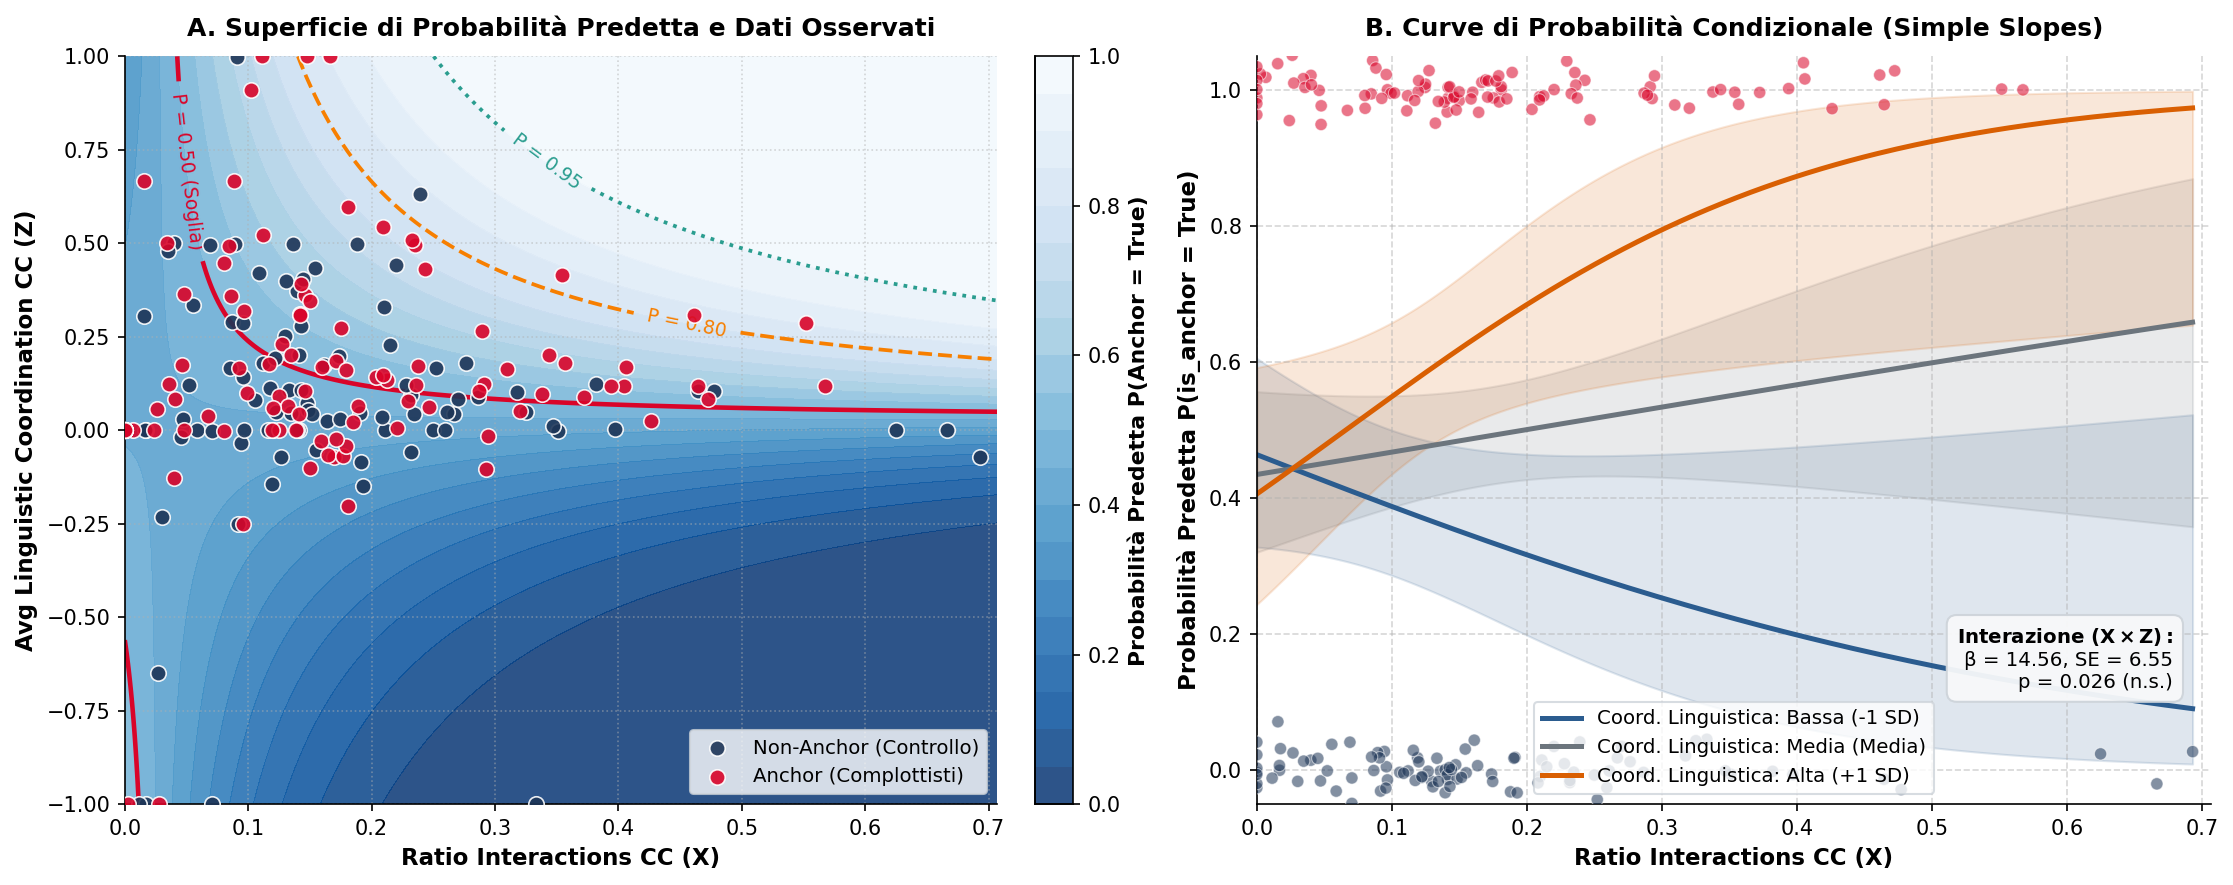

In [4]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.formula.api as smf

# ==============================================================================
# 1. PREPARAZIONE DATI E FITTING DEL MODELLO LOGISTICO CON INTERAZIONE
# ==============================================================================
df_mod = df.copy()

# Variabile dipendente binaria (1 = Anchor, 0 = Non-Anchor)
df_mod["y"] = (
    df_mod["is_anchor"]
    .astype(str)
    .str.strip()
    .str.lower()
    .isin(["true", "1", "t"])
    .astype(int)
)

# Modello con termine di interazione moltiplicativa (X * Z)
formula = "y ~ ratio_interactions_cc * avg_linguistic_coordination_cc"
mod_res = smf.logit(formula=formula, data=df_mod).fit(disp=False)

# Estrazione parametri e matrice di covarianza
params = mod_res.params
cov_beta = mod_res.cov_params()
p_int = mod_res.pvalues[
    "ratio_interactions_cc:avg_linguistic_coordination_cc"
]
coef_int = mod_res.params[
    "ratio_interactions_cc:avg_linguistic_coordination_cc"
]

# ==============================================================================
# 2. COSTRUZIONE DELLA FIGURA (PANNELLO A + PANNELLO B)
# ==============================================================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6), dpi=150)

# ------------------------------------------------------------------------------
# PANNELLO A: Contorni di Probabilità 2D e Dati Reali
# ------------------------------------------------------------------------------
x_max = df_mod["ratio_interactions_cc"].max()
x_grid = np.linspace(0, x_max * 1.02, 150)
z_min, z_max = (
    df_mod["avg_linguistic_coordination_cc"].min(),
    df_mod["avg_linguistic_coordination_cc"].max(),
)
z_grid = np.linspace(z_min, z_max, 150)
XX, ZZ = np.meshgrid(x_grid, z_grid)

# Matrice disegno per la griglia 2D
grid_design = np.column_stack(
    [np.ones(XX.size), XX.ravel(), ZZ.ravel(), XX.ravel() * ZZ.ravel()]
)
eta_grid = grid_design @ params
prob_grid = (1 / (1 + np.exp(-eta_grid))).reshape(XX.shape)

# Riempimento gradiente di probabilità
contour = ax1.contourf(
    XX,
    ZZ,
    prob_grid,
    levels=np.linspace(0, 1, 21),
    cmap="Blues_r",
    alpha=0.85,
)
cbar = plt.colorbar(contour, ax=ax1, fraction=0.046, pad=0.04)
cbar.set_label(
    "Probabilità Predetta P(Anchor = True)", fontsize=10.5, fontweight="bold"
)
cbar.set_ticks(np.linspace(0, 1, 6))

# Linee di livello specifiche (Decision Boundaries)
cs = ax1.contour(
    XX,
    ZZ,
    prob_grid,
    levels=[0.50, 0.80, 0.95],
    colors=["#d90429", "#f77f00", "#2a9d8f"],
    linewidths=[2.2, 1.8, 1.8],
    linestyles=["-", "--", ":"],
)
ax1.clabel(
    cs,
    fmt={0.50: "P = 0.50 (Soglia)", 0.80: "P = 0.80", 0.95: "P = 0.95"},
    fontsize=9,
)

# Overlay utenti reali osservati
for is_anc, col, lbl in [
    (0, "#1d3557", "Non-Anchor (Controllo)"),
    (1, "#d90429", "Anchor (Complottisti)"),
]:
    mask = df_mod["y"] == is_anc
    ax1.scatter(
        df_mod.loc[mask, "ratio_interactions_cc"],
        df_mod.loc[mask, "avg_linguistic_coordination_cc"],
        c=col,
        edgecolors="white",
        linewidth=0.8,
        s=55,
        alpha=0.9,
        label=lbl,
        zorder=5,
    )

ax1.set_xlabel("Ratio Interactions CC (X)", fontsize=11, fontweight="bold")
ax1.set_ylabel(
    "Avg Linguistic Coordination CC (Z)", fontsize=11, fontweight="bold"
)
ax1.set_title(
    "A. Superficie di Probabilità Predetta e Dati Osservati",
    fontsize=12,
    fontweight="bold",
    pad=10,
)
ax1.legend(
    loc="lower right",
    frameon=True,
    facecolor="white",
    edgecolor="#ced4da",
    fontsize=9.5,
)
ax1.grid(True, linestyle=":", alpha=0.5)

# ------------------------------------------------------------------------------
# PANNELLO B: Simple Slopes (Curve a -1 SD, Media, +1 SD con CI 95%)
# ------------------------------------------------------------------------------
z_mean = df_mod["avg_linguistic_coordination_cc"].mean()
z_std = df_mod["avg_linguistic_coordination_cc"].std()

z_slices = [
    ("Bassa (-1 SD)", z_mean - z_std, "#2b5c8f"),
    ("Media (Media)", z_mean, "#6c757d"),
    ("Alta (+1 SD)", z_mean + z_std, "#d95f02"),
]

x_curve = np.linspace(0, x_max, 200)

for label, z_val, col in z_slices:
    # Matrice di disegno per la curva specifica
    X_d = np.column_stack(
        [
            np.ones_like(x_curve),
            x_curve,
            np.full_like(x_curve, z_val),
            x_curve * z_val,
        ]
    )

    # Calcolo fitted values ed errore standard (Delta method su logit)
    eta = X_d @ params
    se_eta = np.sqrt(np.diag(X_d @ cov_beta @ X_d.T))

    p_pred = 1 / (1 + np.exp(-eta))
    p_low = 1 / (1 + np.exp(-(eta - 1.96 * se_eta)))
    p_high = 1 / (1 + np.exp(-(eta + 1.96 * se_eta)))

    ax2.plot(
        x_curve,
        p_pred,
        color=col,
        lw=2.4,
        label=f"Coord. Linguistica: {label}",
    )
    ax2.fill_between(x_curve, p_low, p_high, color=col, alpha=0.15)

# Punti empirici con leggero jitter verticale
jitter = np.random.normal(0, 0.02, size=len(df_mod))
scatter_colors = np.where(df_mod["y"] == 1, "#d90429", "#1d3557")
ax2.scatter(
    df_mod["ratio_interactions_cc"],
    df_mod["y"] + jitter,
    c=scatter_colors,
    alpha=0.55,
    s=35,
    edgecolors="white",
    lw=0.5,
    zorder=5,
)

# Badge con metadati statistici formali dell'interazione
stats_badge = (
    r"$\bf{Interazione\ (X \times Z):}$"
    + "\n"
    + f"β = {coef_int:.2f}, SE = {mod_res.bse['ratio_interactions_cc:avg_linguistic_coordination_cc']:.2f}\n"
    + f"p = {p_int:.3f} (n.s.)"
)
ax2.text(
    0.96,
    0.15,
    stats_badge,
    transform=ax2.transAxes,
    fontsize=9.5,
    ha="right",
    va="bottom",
    bbox=dict(
        boxstyle="round,pad=0.5",
        facecolor="#f8f9fa",
        edgecolor="#ced4da",
        alpha=0.95,
    ),
)

ax2.set_ylim(-0.05, 1.05)
ax2.set_xlim(0, x_max * 1.02)
ax2.set_xlabel("Ratio Interactions CC (X)", fontsize=11, fontweight="bold")
ax2.set_ylabel(
    "Probabilità Predetta P(is_anchor = True)", fontsize=11, fontweight="bold"
)
ax2.set_title(
    "B. Curve di Probabilità Condizionale (Simple Slopes)",
    fontsize=12,
    fontweight="bold",
    pad=10,
)
ax2.legend(
    loc="lower center",
    frameon=True,
    facecolor="white",
    edgecolor="#ced4da",
    fontsize=9.5,
)
ax2.grid(True, linestyle="--", alpha=0.5)

sns.despine(fig=fig)
plt.tight_layout()
plt.show()

Modello 2: Conspiracy Score Subreddit × Somiglianza dei Contenuti

• Variabile Indipendente (X): subreddit_preobs_conspiracy_score

• Variabile Dipendente (Y): is_anchor (True / False)

• Moderatore (Z): avg_conspiracy_similarity

• Domanda di ricerca: La frequentazione di subreddit complottisti aumenta la probabilità di fondare una propria community soprattutto per quegli utenti che producono già contenuti semanticamente simili alle teorie del complotto?

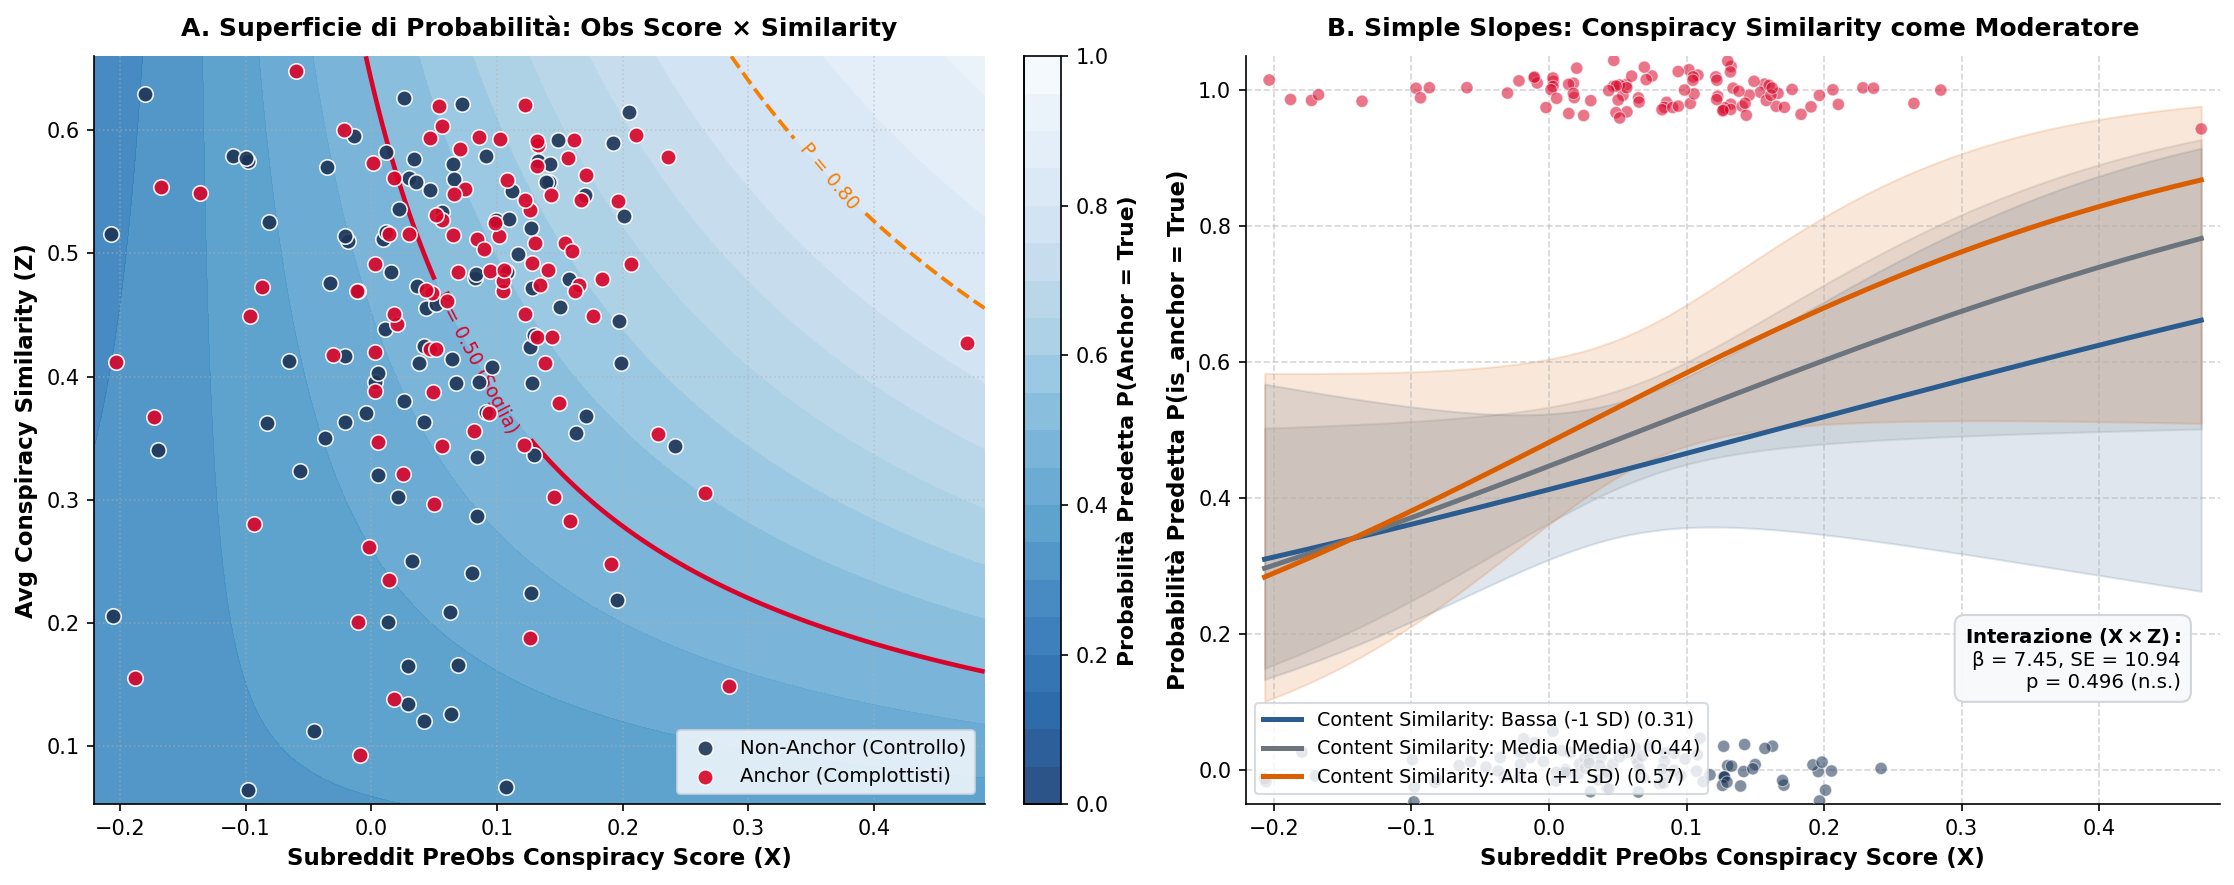

In [5]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.formula.api as smf

# 1. Preparazione Dati
df_mod1 = df.copy()
if (
    "subreddit_preobs_conspiracy_score" not in df_mod1.columns
    and "subreddits_preobs_conspiracy_score" in df_mod1.columns
):
    df_mod1["subreddit_preobs_conspiracy_score"] = df_mod1[
        "subreddits_preobs_conspiracy_score"
    ]

df_mod1["y"] = (
    df_mod1["is_anchor"]
    .astype(str)
    .str.strip()
    .str.lower()
    .isin(["true", "1", "t"])
    .astype(int)
)

x_col = "subreddit_preobs_conspiracy_score"
z_col = "avg_conspiracy_similarity"

# 2. Modello Logistico con Interazione
formula = f"y ~ {x_col} * {z_col}"
mod_res = smf.logit(formula=formula, data=df_mod1).fit(disp=False)

params = mod_res.params
cov_beta = mod_res.cov_params()
int_key = f"{x_col}:{z_col}" if f"{x_col}:{z_col}" in params else f"{z_col}:{x_col}"
coef_int = params[int_key]
se_int = mod_res.bse[int_key]
p_int = mod_res.pvalues[int_key]

# 3. Costruzione Figura (2 Pannelli)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6), dpi=150)

# PANNELLO A: Superficie 2D
x_min, x_max = df_mod1[x_col].min(), df_mod1[x_col].max()
x_span = x_max - x_min
x_grid = np.linspace(x_min - 0.02 * x_span, x_max + 0.02 * x_span, 150)

z_min, z_max = df_mod1[z_col].min(), df_mod1[z_col].max()
z_span = z_max - z_min
z_grid = np.linspace(z_min - 0.02 * z_span, z_max + 0.02 * z_span, 150)

XX, ZZ = np.meshgrid(x_grid, z_grid)
grid_design = np.column_stack(
    [np.ones(XX.size), XX.ravel(), ZZ.ravel(), XX.ravel() * ZZ.ravel()]
)
eta_grid = grid_design @ params
prob_grid = (1 / (1 + np.exp(-eta_grid))).reshape(XX.shape)

contour = ax1.contourf(
    XX,
    ZZ,
    prob_grid,
    levels=np.linspace(0, 1, 21),
    cmap="Blues_r",
    alpha=0.85,
)
cbar = plt.colorbar(contour, ax=ax1, fraction=0.046, pad=0.04)
cbar.set_label(
    "Probabilità Predetta P(Anchor = True)", fontsize=10.5, fontweight="bold"
)
cbar.set_ticks(np.linspace(0, 1, 6))

levels_to_plot = [
    lvl for lvl in [0.50, 0.80, 0.95] if prob_grid.min() < lvl < prob_grid.max()
]
if levels_to_plot:
    colors_map = {0.50: "#d90429", 0.80: "#f77f00", 0.95: "#2a9d8f"}
    cs = ax1.contour(
        XX,
        ZZ,
        prob_grid,
        levels=levels_to_plot,
        colors=[colors_map[lvl] for lvl in levels_to_plot],
        linewidths=[2.2 if lvl == 0.5 else 1.8 for lvl in levels_to_plot],
        linestyles=[
            "-" if lvl == 0.5 else ("--" if lvl == 0.8 else ":")
            for lvl in levels_to_plot
        ],
    )
    fmt_dict = {
        0.50: "P = 0.50 (Soglia)",
        0.80: "P = 0.80",
        0.95: "P = 0.95",
    }
    ax1.clabel(
        cs, fmt={lvl: fmt_dict[lvl] for lvl in levels_to_plot}, fontsize=9
    )

for is_anc, col, lbl in [
    (0, "#1d3557", "Non-Anchor (Controllo)"),
    (1, "#d90429", "Anchor (Complottisti)"),
]:
    mask = df_mod1["y"] == is_anc
    ax1.scatter(
        df_mod1.loc[mask, x_col],
        df_mod1.loc[mask, z_col],
        c=col,
        edgecolors="white",
        linewidth=0.8,
        s=55,
        alpha=0.9,
        label=lbl,
        zorder=5,
    )

ax1.set_xlabel(
    "Subreddit PreObs Conspiracy Score (X)", fontsize=11, fontweight="bold"
)
ax1.set_ylabel(
    "Avg Conspiracy Similarity (Z)", fontsize=11, fontweight="bold"
)
ax1.set_title(
    "A. Superficie di Probabilità: Obs Score × Similarity",
    fontsize=12,
    fontweight="bold",
    pad=10,
)
ax1.legend(
    loc="lower right",
    frameon=True,
    facecolor="white",
    edgecolor="#ced4da",
    fontsize=9.5,
)
ax1.grid(True, linestyle=":", alpha=0.5)

# PANNELLO B: Simple Slopes
z_mean = df_mod1[z_col].mean()
z_std = df_mod1[z_col].std()
z_slices = [
    ("Bassa (-1 SD)", z_mean - z_std, "#2b5c8f"),
    ("Media (Media)", z_mean, "#6c757d"),
    ("Alta (+1 SD)", z_mean + z_std, "#d95f02"),
]

x_curve = np.linspace(x_min, x_max, 200)
for label, z_val, col in z_slices:
    X_d = np.column_stack(
        [
            np.ones_like(x_curve),
            x_curve,
            np.full_like(x_curve, z_val),
            x_curve * z_val,
        ]
    )
    eta = X_d @ params
    se_eta = np.sqrt(np.diag(X_d @ cov_beta @ X_d.T))

    p_pred = 1 / (1 + np.exp(-eta))
    p_low = 1 / (1 + np.exp(-(eta - 1.96 * se_eta)))
    p_high = 1 / (1 + np.exp(-(eta + 1.96 * se_eta)))

    ax2.plot(
        x_curve,
        p_pred,
        color=col,
        lw=2.4,
        label=f"Content Similarity: {label} ({z_val:.2f})",
    )
    ax2.fill_between(x_curve, p_low, p_high, color=col, alpha=0.15)

jitter = np.random.normal(0, 0.02, size=len(df_mod1))
scatter_colors = np.where(df_mod1["y"] == 1, "#d90429", "#1d3557")
ax2.scatter(
    df_mod1[x_col],
    df_mod1["y"] + jitter,
    c=scatter_colors,
    alpha=0.55,
    s=35,
    edgecolors="white",
    lw=0.5,
    zorder=5,
)

sig_str = (
    "p < 0.001***"
    if p_int < 0.001
    else (f"p = {p_int:.3f}*" if p_int < 0.05 else f"p = {p_int:.3f} (n.s.)")
)
stats_badge = (
    r"$\bf{Interazione\ (X \times Z):}$"
    + "\n"
    + f"β = {coef_int:.2f}, SE = {se_int:.2f}\n"
    + f"{sig_str}"
)
ax2.text(
    0.96,
    0.15,
    stats_badge,
    transform=ax2.transAxes,
    fontsize=9.5,
    ha="right",
    va="bottom",
    bbox=dict(
        boxstyle="round,pad=0.5",
        facecolor="#f8f9fa",
        edgecolor="#ced4da",
        alpha=0.95,
    ),
)

ax2.set_ylim(-0.05, 1.05)
ax2.set_xlim(x_min - 0.02 * x_span, x_max + 0.02 * x_span)
ax2.set_xlabel(
    "Subreddit PreObs Conspiracy Score (X)", fontsize=11, fontweight="bold"
)
ax2.set_ylabel(
    "Probabilità Predetta P(is_anchor = True)", fontsize=11, fontweight="bold"
)
ax2.set_title(
    "B. Simple Slopes: Conspiracy Similarity come Moderatore",
    fontsize=12,
    fontweight="bold",
    pad=10,
)
ax2.legend(
    loc="lower left",
    frameon=True,
    facecolor="white",
    edgecolor="#ced4da",
    fontsize=9.2,
)
ax2.grid(True, linestyle="--", alpha=0.5)

sns.despine(fig=fig)
plt.tight_layout()
plt.show()

Modello 3: Conspiracy Score Subreddit × Contributi Negativi (Rigetto Sociale)

• Variabile Indipendente (X): subreddit_obs_conspiracy_score

• Variabile Dipendente (Y): is_anchor (True / False)

• Moderatore (Z): ratio_negative_contributions

• Domanda di ricerca: L'esposizione ad ambienti complottisti spinge verso la fondazione di una comunità autonoma con maggiore intensità se l'utente sperimenta attrito sociale (downvote o post respinti)?

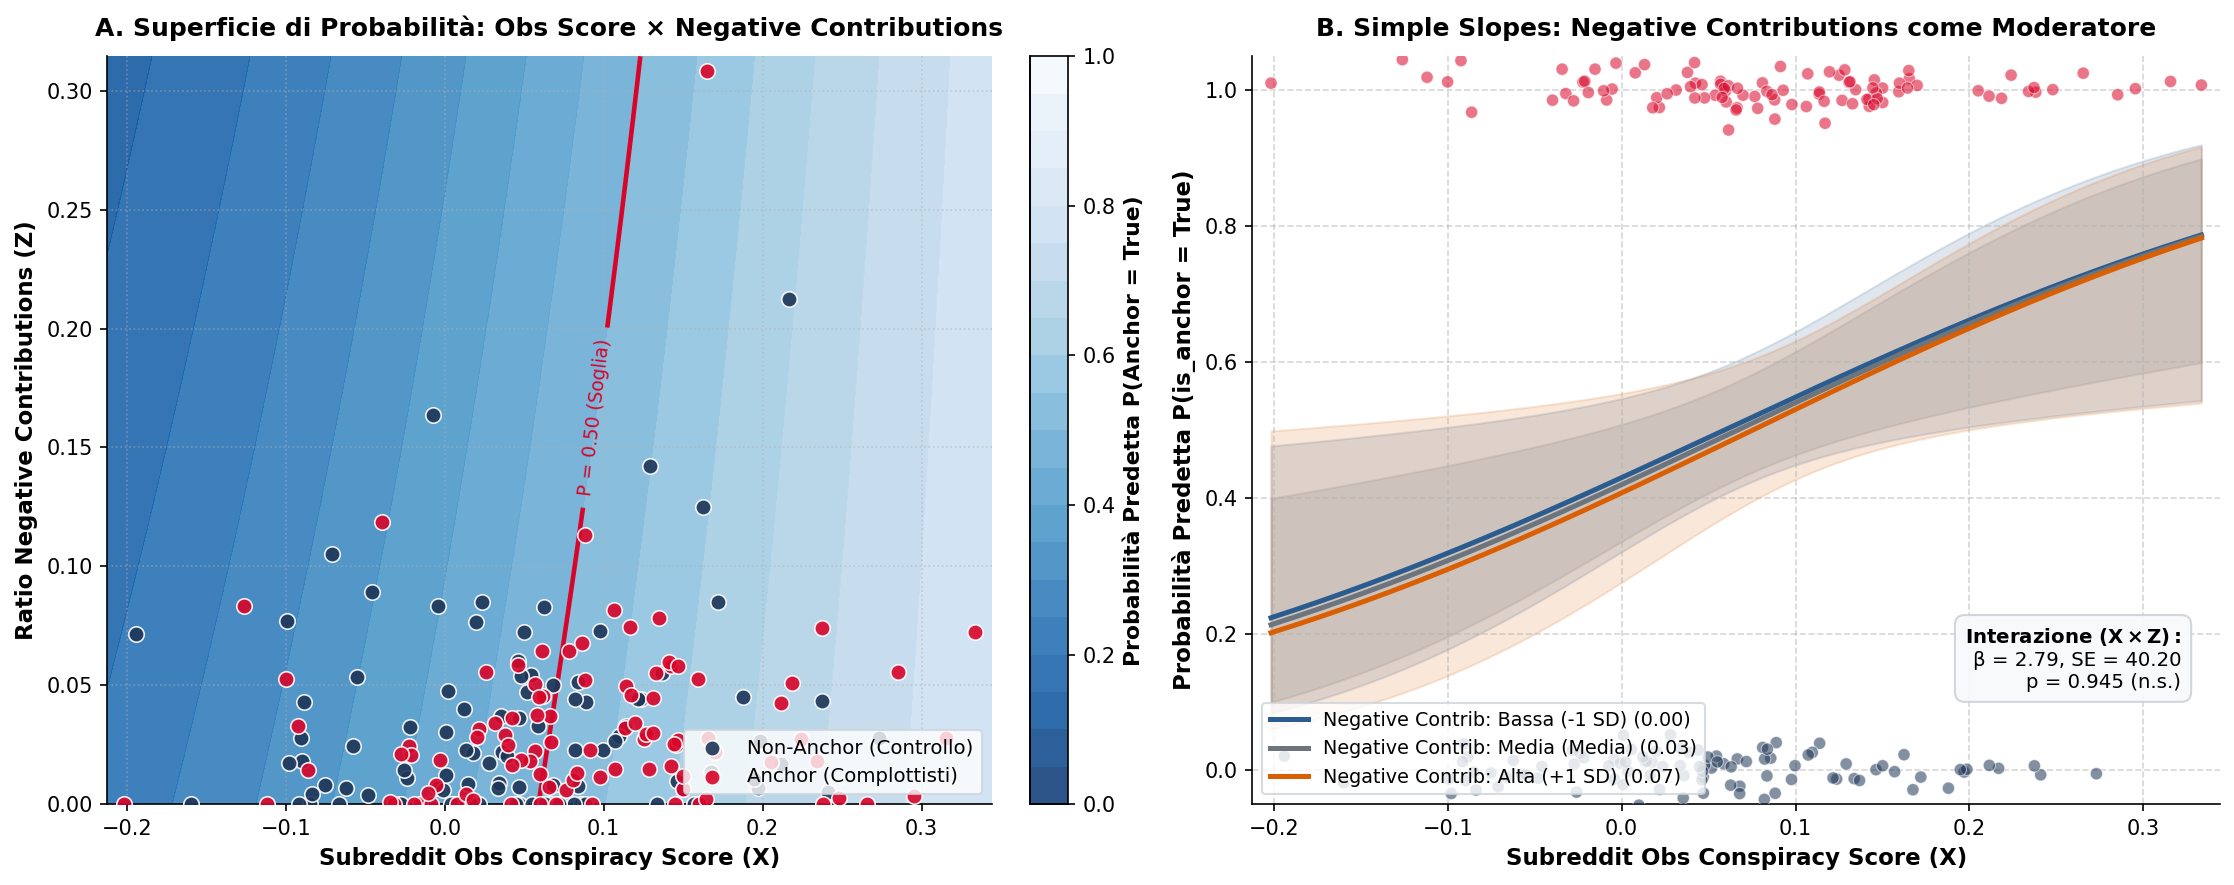

In [6]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.formula.api as smf

# 1. Preparazione Dati
df_mod2 = df.copy()
if (
    "subreddit_obs_conspiracy_score" not in df_mod2.columns
    and "subreddits_obs_conspiracy_score" in df_mod2.columns
):
    df_mod2["subreddit_obs_conspiracy_score"] = df_mod2[
        "subreddits_obs_conspiracy_score"
    ]

df_mod2["y"] = (
    df_mod2["is_anchor"]
    .astype(str)
    .str.strip()
    .str.lower()
    .isin(["true", "1", "t"])
    .astype(int)
)

x_col = "subreddit_obs_conspiracy_score"
z_col = "ratio_negative_contributions"

# 2. Fitting del Modello
formula = f"y ~ {x_col} * {z_col}"
mod_res = smf.logit(formula=formula, data=df_mod2).fit(disp=False)

params = mod_res.params
cov_beta = mod_res.cov_params()
int_key = f"{x_col}:{z_col}" if f"{x_col}:{z_col}" in params else f"{z_col}:{x_col}"
coef_int = params[int_key]
se_int = mod_res.bse[int_key]
p_int = mod_res.pvalues[int_key]

# 3. Plotting
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6), dpi=150)

# PANNELLO A
x_min, x_max = df_mod2[x_col].min(), df_mod2[x_col].max()
x_span = x_max - x_min
x_grid = np.linspace(x_min - 0.02 * x_span, x_max + 0.02 * x_span, 150)

z_min, z_max = df_mod2[z_col].min(), df_mod2[z_col].max()
z_span = z_max - z_min
z_grid = np.linspace(z_min, z_max + 0.02 * z_span, 150)

XX, ZZ = np.meshgrid(x_grid, z_grid)
grid_design = np.column_stack(
    [np.ones(XX.size), XX.ravel(), ZZ.ravel(), XX.ravel() * ZZ.ravel()]
)
eta_grid = grid_design @ params
prob_grid = (1 / (1 + np.exp(-eta_grid))).reshape(XX.shape)

contour = ax1.contourf(
    XX,
    ZZ,
    prob_grid,
    levels=np.linspace(0, 1, 21),
    cmap="Blues_r",
    alpha=0.85,
)
cbar = plt.colorbar(contour, ax=ax1, fraction=0.046, pad=0.04)
cbar.set_label(
    "Probabilità Predetta P(Anchor = True)", fontsize=10.5, fontweight="bold"
)
cbar.set_ticks(np.linspace(0, 1, 6))

levels_to_plot = [
    lvl for lvl in [0.50, 0.80, 0.95] if prob_grid.min() < lvl < prob_grid.max()
]
if levels_to_plot:
    colors_map = {0.50: "#d90429", 0.80: "#f77f00", 0.95: "#2a9d8f"}
    cs = ax1.contour(
        XX,
        ZZ,
        prob_grid,
        levels=levels_to_plot,
        colors=[colors_map[lvl] for lvl in levels_to_plot],
        linewidths=[2.2 if lvl == 0.5 else 1.8 for lvl in levels_to_plot],
        linestyles=[
            "-" if lvl == 0.5 else ("--" if lvl == 0.8 else ":")
            for lvl in levels_to_plot
        ],
    )
    fmt_dict = {
        0.50: "P = 0.50 (Soglia)",
        0.80: "P = 0.80",
        0.95: "P = 0.95",
    }
    ax1.clabel(
        cs, fmt={lvl: fmt_dict[lvl] for lvl in levels_to_plot}, fontsize=9
    )

for is_anc, col, lbl in [
    (0, "#1d3557", "Non-Anchor (Controllo)"),
    (1, "#d90429", "Anchor (Complottisti)"),
]:
    mask = df_mod2["y"] == is_anc
    ax1.scatter(
        df_mod2.loc[mask, x_col],
        df_mod2.loc[mask, z_col],
        c=col,
        edgecolors="white",
        linewidth=0.8,
        s=55,
        alpha=0.9,
        label=lbl,
        zorder=5,
    )

ax1.set_xlabel(
    "Subreddit Obs Conspiracy Score (X)", fontsize=11, fontweight="bold"
)
ax1.set_ylabel(
    "Ratio Negative Contributions (Z)", fontsize=11, fontweight="bold"
)
ax1.set_title(
    "A. Superficie di Probabilità: Obs Score × Negative Contributions",
    fontsize=12,
    fontweight="bold",
    pad=10,
)
ax1.legend(
    loc="lower right",
    frameon=True,
    facecolor="white",
    edgecolor="#ced4da",
    fontsize=9.5,
)
ax1.grid(True, linestyle=":", alpha=0.5)

# PANNELLO B
z_mean = df_mod2[z_col].mean()
z_std = df_mod2[z_col].std()
z_low = max(0.0, z_mean - z_std)
z_slices = [
    ("Bassa (-1 SD)", z_low, "#2b5c8f"),
    ("Media (Media)", z_mean, "#6c757d"),
    ("Alta (+1 SD)", z_mean + z_std, "#d95f02"),
]

x_curve = np.linspace(x_min, x_max, 200)
for label, z_val, col in z_slices:
    X_d = np.column_stack(
        [
            np.ones_like(x_curve),
            x_curve,
            np.full_like(x_curve, z_val),
            x_curve * z_val,
        ]
    )
    eta = X_d @ params
    se_eta = np.sqrt(np.diag(X_d @ cov_beta @ X_d.T))

    p_pred = 1 / (1 + np.exp(-eta))
    p_low = 1 / (1 + np.exp(-(eta - 1.96 * se_eta)))
    p_high = 1 / (1 + np.exp(-(eta + 1.96 * se_eta)))

    ax2.plot(
        x_curve,
        p_pred,
        color=col,
        lw=2.4,
        label=f"Negative Contrib: {label} ({z_val:.2f})",
    )
    ax2.fill_between(x_curve, p_low, p_high, color=col, alpha=0.15)

jitter = np.random.normal(0, 0.02, size=len(df_mod2))
scatter_colors = np.where(df_mod2["y"] == 1, "#d90429", "#1d3557")
ax2.scatter(
    df_mod2[x_col],
    df_mod2["y"] + jitter,
    c=scatter_colors,
    alpha=0.55,
    s=35,
    edgecolors="white",
    lw=0.5,
    zorder=5,
)

sig_str = (
    "p < 0.001***"
    if p_int < 0.001
    else (f"p = {p_int:.3f}*" if p_int < 0.05 else f"p = {p_int:.3f} (n.s.)")
)
stats_badge = (
    r"$\bf{Interazione\ (X \times Z):}$"
    + "\n"
    + f"β = {coef_int:.2f}, SE = {se_int:.2f}\n"
    + f"{sig_str}"
)
ax2.text(
    0.96,
    0.15,
    stats_badge,
    transform=ax2.transAxes,
    fontsize=9.5,
    ha="right",
    va="bottom",
    bbox=dict(
        boxstyle="round,pad=0.5",
        facecolor="#f8f9fa",
        edgecolor="#ced4da",
        alpha=0.95,
    ),
)

ax2.set_ylim(-0.05, 1.05)
ax2.set_xlim(x_min - 0.02 * x_span, x_max + 0.02 * x_span)
ax2.set_xlabel(
    "Subreddit Obs Conspiracy Score (X)", fontsize=11, fontweight="bold"
)
ax2.set_ylabel(
    "Probabilità Predetta P(is_anchor = True)", fontsize=11, fontweight="bold"
)
ax2.set_title(
    "B. Simple Slopes: Negative Contributions come Moderatore",
    fontsize=12,
    fontweight="bold",
    pad=10,
)
ax2.legend(
    loc="lower left",
    frameon=True,
    facecolor="white",
    edgecolor="#ced4da",
    fontsize=9.2,
)
ax2.grid(True, linestyle="--", alpha=0.5)

sns.despine(fig=fig)
plt.tight_layout()
plt.show()

Modello 4: Conspiracy Score Subreddit × Crescente Esclusività Partecipativa

• Variabile Indipendente (X): subreddit_obs_conspiracy_score

• Variabile Dipendente (Y): is_anchor (True / False)

• Moderatore (Z): growing_exclusivity_contributions

• Domanda di ricerca: L'impatto dell'ambiente complottista sulla transizione a fondatore diventa più forte man mano che l'utente isola la propria attività, concentrandola in modo progressivamente esclusivo in quello spazio?

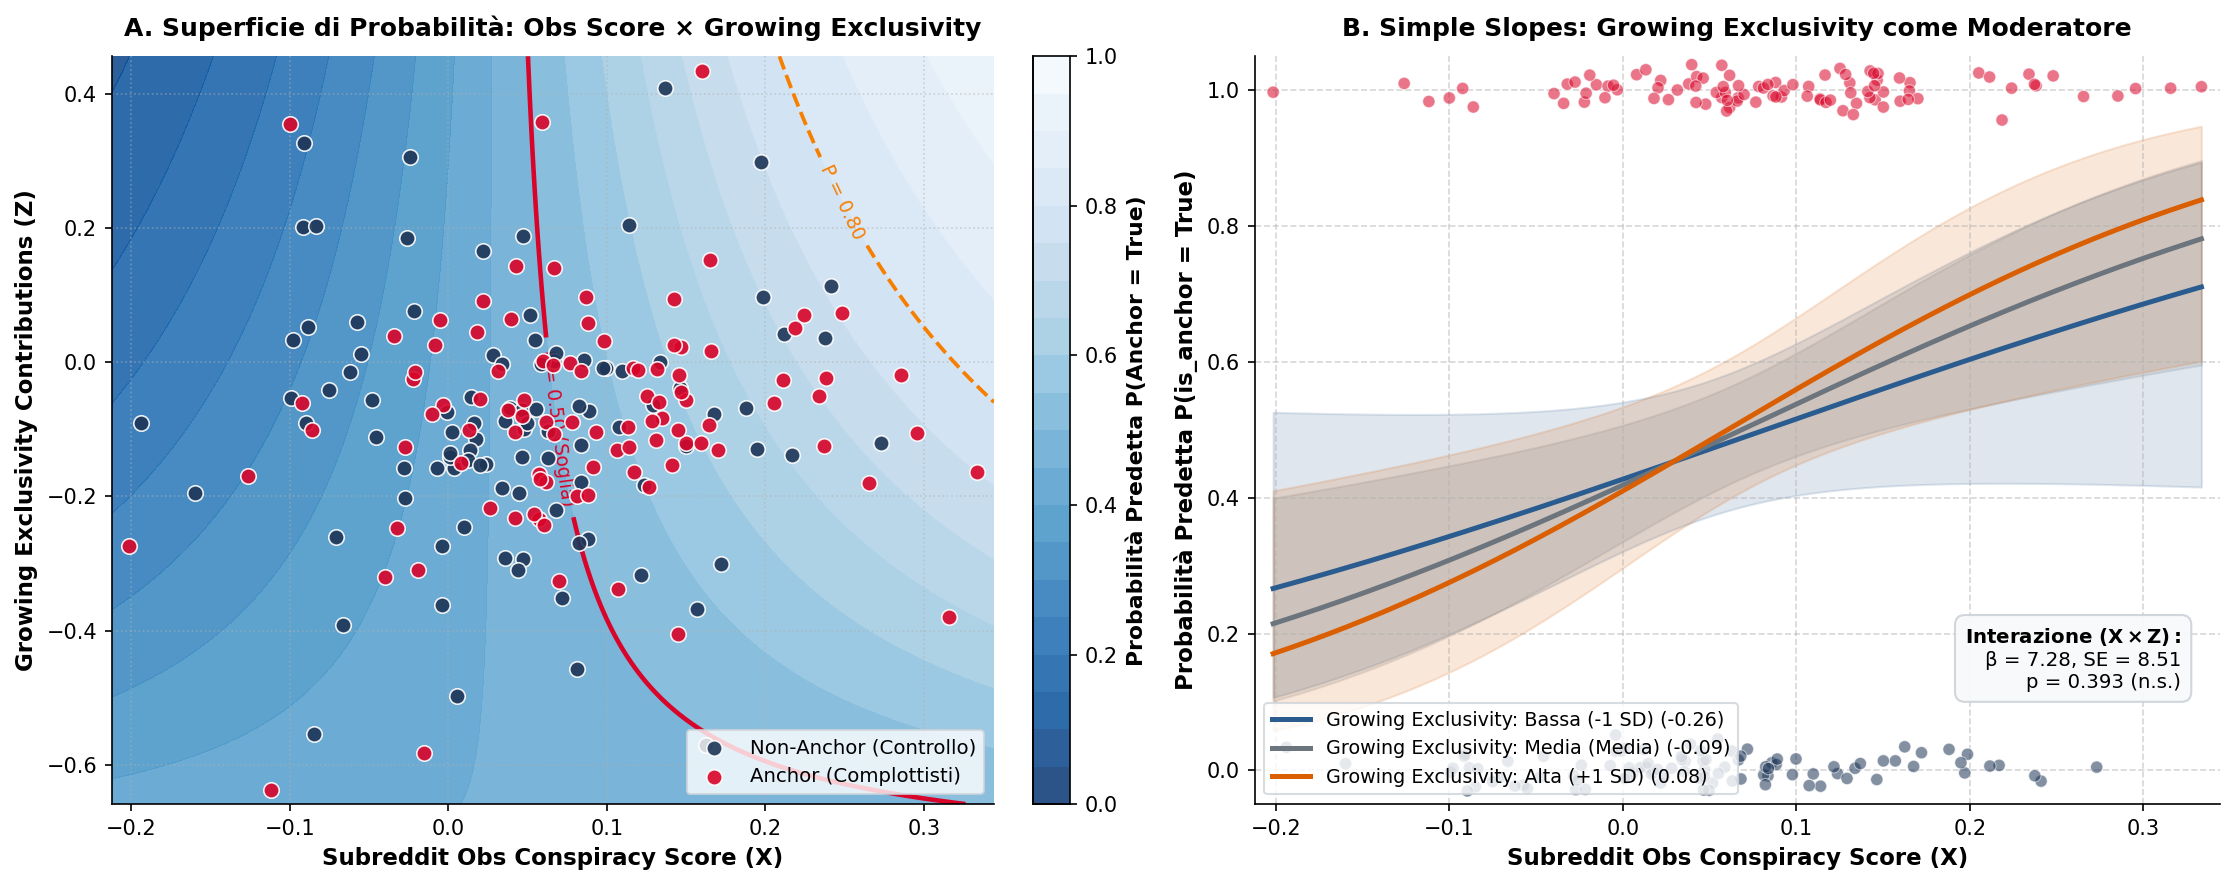

In [7]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.formula.api as smf

# 1. Preparazione Dati
df_mod3 = df.copy()
if (
    "subreddit_obs_conspiracy_score" not in df_mod3.columns
    and "subreddits_obs_conspiracy_score" in df_mod3.columns
):
    df_mod3["subreddit_obs_conspiracy_score"] = df_mod3[
        "subreddits_obs_conspiracy_score"
    ]
if (
    "growing_exclusivity_contributions" not in df_mod3.columns
    and "growing_exclusibity_contributions" in df_mod3.columns
):
    df_mod3["growing_exclusivity_contributions"] = df_mod3[
        "growing_exclusibity_contributions"
    ]

df_mod3["y"] = (
    df_mod3["is_anchor"]
    .astype(str)
    .str.strip()
    .str.lower()
    .isin(["true", "1", "t"])
    .astype(int)
)

x_col = "subreddit_obs_conspiracy_score"
z_col = "growing_exclusivity_contributions"

# 2. Fitting del Modello
formula = f"y ~ {x_col} * {z_col}"
mod_res = smf.logit(formula=formula, data=df_mod3).fit(disp=False)

params = mod_res.params
cov_beta = mod_res.cov_params()
int_key = f"{x_col}:{z_col}" if f"{x_col}:{z_col}" in params else f"{z_col}:{x_col}"
coef_int = params[int_key]
se_int = mod_res.bse[int_key]
p_int = mod_res.pvalues[int_key]

# 3. Plotting
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6), dpi=150)

# PANNELLO A
x_min, x_max = df_mod3[x_col].min(), df_mod3[x_col].max()
x_span = x_max - x_min
x_grid = np.linspace(x_min - 0.02 * x_span, x_max + 0.02 * x_span, 150)

z_min, z_max = df_mod3[z_col].min(), df_mod3[z_col].max()
z_span = z_max - z_min
z_grid = np.linspace(z_min - 0.02 * z_span, z_max + 0.02 * z_span, 150)

XX, ZZ = np.meshgrid(x_grid, z_grid)
grid_design = np.column_stack(
    [np.ones(XX.size), XX.ravel(), ZZ.ravel(), XX.ravel() * ZZ.ravel()]
)
eta_grid = grid_design @ params
prob_grid = (1 / (1 + np.exp(-eta_grid))).reshape(XX.shape)

contour = ax1.contourf(
    XX,
    ZZ,
    prob_grid,
    levels=np.linspace(0, 1, 21),
    cmap="Blues_r",
    alpha=0.85,
)
cbar = plt.colorbar(contour, ax=ax1, fraction=0.046, pad=0.04)
cbar.set_label(
    "Probabilità Predetta P(Anchor = True)", fontsize=10.5, fontweight="bold"
)
cbar.set_ticks(np.linspace(0, 1, 6))

levels_to_plot = [
    lvl for lvl in [0.50, 0.80, 0.95] if prob_grid.min() < lvl < prob_grid.max()
]
if levels_to_plot:
    colors_map = {0.50: "#d90429", 0.80: "#f77f00", 0.95: "#2a9d8f"}
    cs = ax1.contour(
        XX,
        ZZ,
        prob_grid,
        levels=levels_to_plot,
        colors=[colors_map[lvl] for lvl in levels_to_plot],
        linewidths=[2.2 if lvl == 0.5 else 1.8 for lvl in levels_to_plot],
        linestyles=[
            "-" if lvl == 0.5 else ("--" if lvl == 0.8 else ":")
            for lvl in levels_to_plot
        ],
    )
    fmt_dict = {
        0.50: "P = 0.50 (Soglia)",
        0.80: "P = 0.80",
        0.95: "P = 0.95",
    }
    ax1.clabel(
        cs, fmt={lvl: fmt_dict[lvl] for lvl in levels_to_plot}, fontsize=9
    )

for is_anc, col, lbl in [
    (0, "#1d3557", "Non-Anchor (Controllo)"),
    (1, "#d90429", "Anchor (Complottisti)"),
]:
    mask = df_mod3["y"] == is_anc
    ax1.scatter(
        df_mod3.loc[mask, x_col],
        df_mod3.loc[mask, z_col],
        c=col,
        edgecolors="white",
        linewidth=0.8,
        s=55,
        alpha=0.9,
        label=lbl,
        zorder=5,
    )

ax1.set_xlabel(
    "Subreddit Obs Conspiracy Score (X)", fontsize=11, fontweight="bold"
)
ax1.set_ylabel(
    "Growing Exclusivity Contributions (Z)", fontsize=11, fontweight="bold"
)
ax1.set_title(
    "A. Superficie di Probabilità: Obs Score × Growing Exclusivity",
    fontsize=12,
    fontweight="bold",
    pad=10,
)
ax1.legend(
    loc="lower right",
    frameon=True,
    facecolor="white",
    edgecolor="#ced4da",
    fontsize=9.5,
)
ax1.grid(True, linestyle=":", alpha=0.5)

# PANNELLO B
z_mean = df_mod3[z_col].mean()
z_std = df_mod3[z_col].std()
z_slices = [
    ("Bassa (-1 SD)", z_mean - z_std, "#2b5c8f"),
    ("Media (Media)", z_mean, "#6c757d"),
    ("Alta (+1 SD)", z_mean + z_std, "#d95f02"),
]

x_curve = np.linspace(x_min, x_max, 200)
for label, z_val, col in z_slices:
    X_d = np.column_stack(
        [
            np.ones_like(x_curve),
            x_curve,
            np.full_like(x_curve, z_val),
            x_curve * z_val,
        ]
    )
    eta = X_d @ params
    se_eta = np.sqrt(np.diag(X_d @ cov_beta @ X_d.T))

    p_pred = 1 / (1 + np.exp(-eta))
    p_low = 1 / (1 + np.exp(-(eta - 1.96 * se_eta)))
    p_high = 1 / (1 + np.exp(-(eta + 1.96 * se_eta)))

    ax2.plot(
        x_curve,
        p_pred,
        color=col,
        lw=2.4,
        label=f"Growing Exclusivity: {label} ({z_val:.2f})",
    )
    ax2.fill_between(x_curve, p_low, p_high, color=col, alpha=0.15)

jitter = np.random.normal(0, 0.02, size=len(df_mod3))
scatter_colors = np.where(df_mod3["y"] == 1, "#d90429", "#1d3557")
ax2.scatter(
    df_mod3[x_col],
    df_mod3["y"] + jitter,
    c=scatter_colors,
    alpha=0.55,
    s=35,
    edgecolors="white",
    lw=0.5,
    zorder=5,
)

sig_str = (
    "p < 0.001***"
    if p_int < 0.001
    else (f"p = {p_int:.3f}*" if p_int < 0.05 else f"p = {p_int:.3f} (n.s.)")
)
stats_badge = (
    r"$\bf{Interazione\ (X \times Z):}$"
    + "\n"
    + f"β = {coef_int:.2f}, SE = {se_int:.2f}\n"
    + f"{sig_str}"
)
ax2.text(
    0.96,
    0.15,
    stats_badge,
    transform=ax2.transAxes,
    fontsize=9.5,
    ha="right",
    va="bottom",
    bbox=dict(
        boxstyle="round,pad=0.5",
        facecolor="#f8f9fa",
        edgecolor="#ced4da",
        alpha=0.95,
    ),
)

ax2.set_ylim(-0.05, 1.05)
ax2.set_xlim(x_min - 0.02 * x_span, x_max + 0.02 * x_span)
ax2.set_xlabel(
    "Subreddit Obs Conspiracy Score (X)", fontsize=11, fontweight="bold"
)
ax2.set_ylabel(
    "Probabilità Predetta P(is_anchor = True)", fontsize=11, fontweight="bold"
)
ax2.set_title(
    "B. Simple Slopes: Growing Exclusivity come Moderatore",
    fontsize=12,
    fontweight="bold",
    pad=10,
)
ax2.legend(
    loc="lower left",
    frameon=True,
    facecolor="white",
    edgecolor="#ced4da",
    fontsize=9.2,
)
ax2.grid(True, linestyle="--", alpha=0.5)

sns.despine(fig=fig)
plt.tight_layout()
plt.show()

In [8]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.formula.api as smf


def plot_trivariate_interaction(
    df,
    x_col,
    z_col,
    y_col="is_anchor",
    x_bins=3,
    z_bins=2,
    x_labels=None,
    z_labels=None,
    title=None,
    figsize=(8.5, 5.5),
):
    """Genera un Interaction Plot formale per analisi trivariata:

    - X: feature indipendente discretizzata in quantili
    - Hue: moderatore discretizzato in livelli
    - Y: tasso/probabilità continua di is_anchor (con barre di errore CI 95%)
    - Box statistico con coefficiente ed esito del test logistico
    """
    plot_df = df.copy()

    # Normalizzazione alias per evitare discrepanze nei nomi colonna
    if (
        "subreddit_obs_conspiracy_score" not in plot_df.columns
        and "subreddits_obs_conspiracy_score" in plot_df.columns
    ):
        plot_df["subreddit_obs_conspiracy_score"] = plot_df[
            "subreddits_obs_conspiracy_score"
        ]
    if (
        "growing_exclusivity_contributions" not in plot_df.columns
        and "growing_exclusibity_contributions" in plot_df.columns
    ):
        plot_df["growing_exclusivity_contributions"] = plot_df[
            "growing_exclusibity_contributions"
        ]

    # Target numerico binario continuo (0.0 o 1.0)
    if plot_df[y_col].dtype == bool or plot_df[y_col].dtype == object:
        plot_df["y_num"] = (
            plot_df[y_col]
            .astype(str)
            .str.strip()
            .str.lower()
            .isin(["true", "1", "t"])
            .astype(float)
        )
    else:
        plot_df["y_num"] = plot_df[y_col].astype(float)

    # Stima del modello logistico continuo per estrarre la significatività dell'interazione
    formula = f"y_num ~ {x_col} * {z_col}"
    mod_res = smf.logit(formula=formula, data=plot_df).fit(disp=False)
    int_term = (
        f"{x_col}:{z_col}"
        if f"{x_col}:{z_col}" in mod_res.params
        else f"{z_col}:{x_col}"
    )
    p_int = mod_res.pvalues[int_term]
    coef_int = mod_res.params[int_term]

    # Discretizzazione X (in quantili bilanciati)
    if x_labels is None:
        x_labels = (
            ["Basso", "Medio", "Alto"] if x_bins == 3 else ["Basso", "Alto"]
        )
    plot_df["x_binned"] = pd.qcut(
        plot_df[x_col], q=x_bins, labels=x_labels, duplicates="drop"
    )

    # Discretizzazione Z (Moderatore, es. mediana: Basso vs Alto)
    if z_labels is None:
        z_labels = (
            ["Moderatore Basso", "Moderatore Alto"]
            if z_bins == 2
            else ["Mod. Basso", "Mod. Medio", "Mod. Alto"]
        )
    plot_df["z_binned"] = pd.qcut(
        plot_df[z_col], q=z_bins, labels=z_labels, duplicates="drop"
    )

    # Palette colori
    palette = (
        ["#2b5c8f", "#d95f02"]
        if z_bins == 2
        else ["#2b5c8f", "#6c757d", "#d95f02"]
    )

    # Costruzione della figura
    fig, ax = plt.subplots(figsize=figsize, dpi=150)

    sns.pointplot(
        data=plot_df,
        x="x_binned",
        y="y_num",
        hue="z_binned",
        palette=palette,
        markers=["o", "s", "^"][: len(z_labels)],
        linestyles=["-", "--", ":"][: len(z_labels)],
        dodge=0.15,
        capsize=0.08,
        ax=ax,
    )

    # Badge con metadati statistici formali dell'interazione
    if p_int < 0.001:
        p_str = "p < 0.001***"
    elif p_int < 0.01:
        p_str = f"p = {p_int:.3f}**"
    elif p_int < 0.05:
        p_str = f"p = {p_int:.3f}*"
    else:
        p_str = f"p = {p_int:.3f} (n.s.)"

    stats_box = (
        r"$\bf{Test\ di\ Interazione:}$"
        + "\n"
        + f"β = {coef_int:.2f}\n"
        + f"{p_str}"
    )
    ax.text(
        0.04,
        0.92,
        stats_box,
        transform=ax.transAxes,
        fontsize=9.5,
        va="top",
        bbox=dict(
            boxstyle="round,pad=0.5",
            facecolor="#f8f9fa",
            edgecolor="#ced4da",
            alpha=0.95,
        ),
    )

    ax.set_ylabel(
        "Tasso di Anchor / Probabilità P(Y=1)", fontsize=11, fontweight="bold"
    )
    ax.set_xlabel(
        f"{x_col.replace('_', ' ').title()} (Discretizzata in Classi)",
        fontsize=11,
        fontweight="bold",
    )
    clean_title = (
        title
        if title
        else f"Interaction Plot: {x_col.replace('_', ' ').title()} × {z_col.replace('_', ' ').title()}"
    )
    ax.set_title(clean_title, fontsize=12.5, fontweight="heavy", pad=12)

    ax.set_ylim(-0.05, 1.05)
    ax.grid(True, linestyle=":", alpha=0.55)
    ax.legend(
        title=z_col.replace("_", " ").title(),
        frameon=True,
        facecolor="white",
        edgecolor="#ced4da",
        loc="lower right",
        fontsize=9.5,
    )
    sns.despine(top=True, right=True)

    plt.tight_layout()
    plt.show()

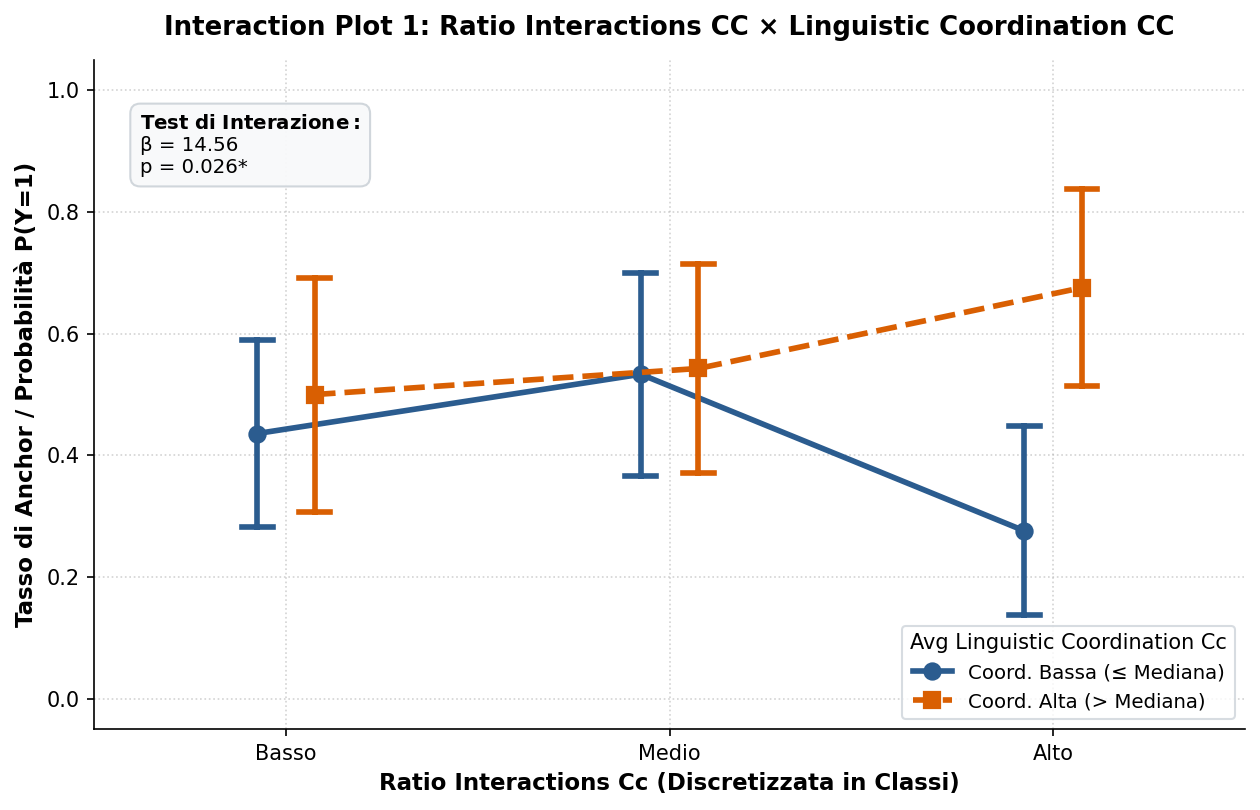

In [9]:
plot_trivariate_interaction(
    df=df,
    x_col="ratio_interactions_cc",
    z_col="avg_linguistic_coordination_cc",
    y_col="is_anchor",
    x_bins=3,
    z_bins=2,
    x_labels=["Basso", "Medio", "Alto"],
    z_labels=["Coord. Bassa (≤ Mediana)", "Coord. Alta (> Mediana)"],
    title="Interaction Plot 1: Ratio Interactions CC × Linguistic Coordination CC",
)

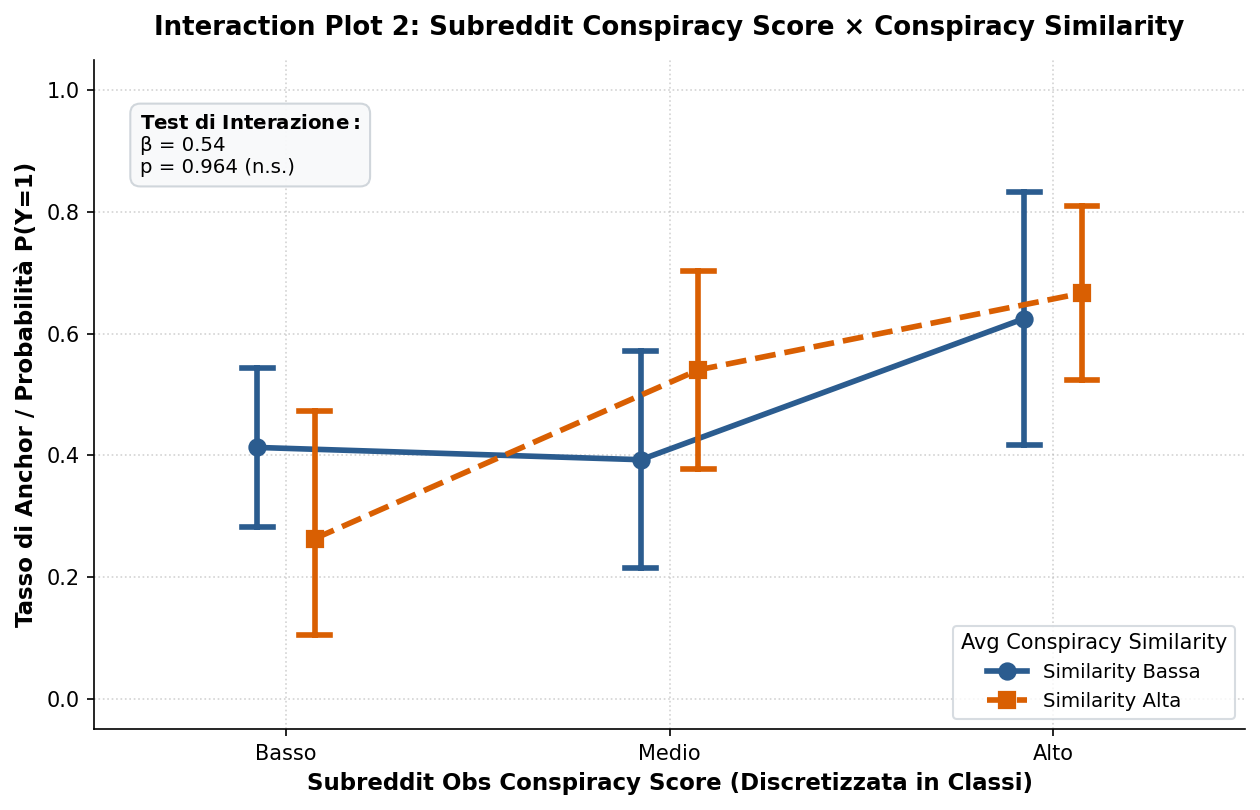

In [10]:
plot_trivariate_interaction(
    df=df,
    x_col="subreddit_obs_conspiracy_score",
    z_col="avg_conspiracy_similarity",
    y_col="is_anchor",
    x_bins=3,
    z_bins=2,
    x_labels=["Basso", "Medio", "Alto"],
    z_labels=["Similarity Bassa", "Similarity Alta"],
    title="Interaction Plot 2: Subreddit Conspiracy Score × Conspiracy Similarity",
)

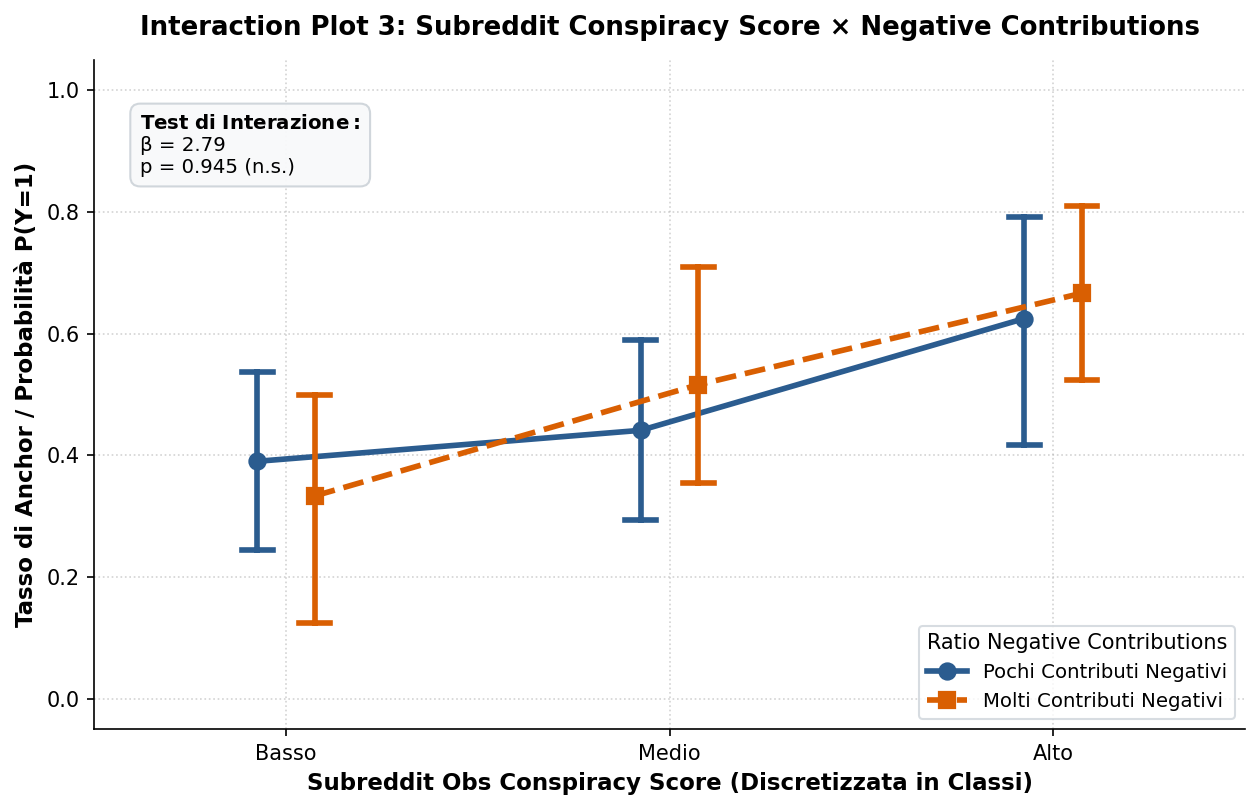

In [11]:
plot_trivariate_interaction(
    df=df,
    x_col="subreddit_obs_conspiracy_score",
    z_col="ratio_negative_contributions",
    y_col="is_anchor",
    x_bins=3,
    z_bins=2,
    x_labels=["Basso", "Medio", "Alto"],
    z_labels=["Pochi Contributi Negativi", "Molti Contributi Negativi"],
    title="Interaction Plot 3: Subreddit Conspiracy Score × Negative Contributions",
)

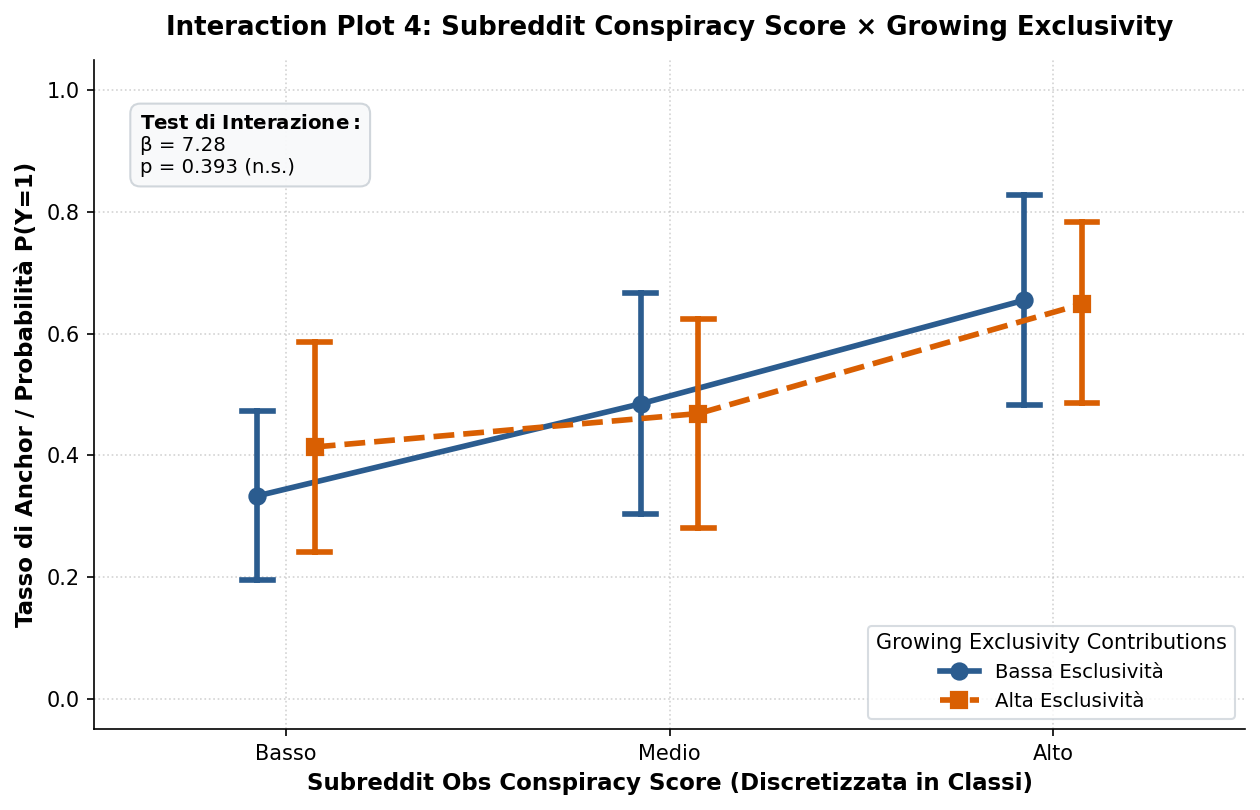

In [12]:
plot_trivariate_interaction(
    df=df,
    x_col="subreddit_obs_conspiracy_score",
    z_col="growing_exclusivity_contributions",
    y_col="is_anchor",
    x_bins=3,
    z_bins=2,
    x_labels=["Basso", "Medio", "Alto"],
    z_labels=["Bassa Esclusività", "Alta Esclusività"],
    title="Interaction Plot 4: Subreddit Conspiracy Score × Growing Exclusivity",
)